# Learning Go potential 

In [ ]:
import json
import os
import pandas as pd
import numpy as np
from tqdm import tqdm
import shutil
from matplotlib import pyplot as plt
import seaborn as sns

while os.path.split(os.getcwd())[-1] != 'calvados-slim':
    os.chdir('..')

from src import curation, utils, constants, visualisation
from src.analysis import slim, features

In [2]:
# Loading curations
with open('data/curation/systems.json') as file:
    systems = json.load(file)
systems_dir = os.path.abspath('data/curation/systems')

scan_dir = 'sim/scan'

In [3]:
# Featurising
X = []
for system in systems:
    X.append(features.featurize(
        system,
        os.path.join('data/curation/systems', system['ID'], 'specific_interactions.txt'),
        features.load_residue_params('data/configurations/residues.csv')
    ))
X = pd.DataFrame(X)

In [4]:
# Getting targets
Y = []

# Looping over systems
scan_dir = 'sim/scan'
for system in os.listdir(scan_dir):
    system_dir = os.path.join(scan_dir, system)

    # Looping over scans
    for k_dir in sorted(os.listdir(system_dir)):

        # Determining k-value
        k = float(k_dir.split('=')[-1])
        kd_csv = os.path.join(system_dir, k_dir, 'kd.csv')
        specific_interactions_txt = os.path.join(system_dir, k_dir, 'specific_interactions.txt')

        # Loading precalculated
        try:
            Kd, Kd_m1sem, Kd_p1sem = pd.read_csv(kd_csv).values[0]
            # Appending results
            Y.append({
                "System": system,
                "k": k,
                "Kd": Kd,
                "Kd-1SEM": Kd_m1sem,
                "Kd+1SEM": Kd_p1sem,
                "dG": slim.dG(Kd),
                "dG-1SEM": slim.dG(Kd_m1sem),
                "dG+1SEM": slim.dG(Kd_p1sem),
            })
        
        except FileNotFoundError:
            continue

Y = pd.DataFrame(Y)

In [5]:
def k_star_ish(subset):
    subset = subset[subset['dG'] > -np.inf]
    mid_dG = (subset['dG'].max() + subset['dG'].min()) / 2
    (idx1, idx2) = (subset['dG'] - mid_dG).abs().sort_values().index[:2]
    return linear_interpolate(
        x = mid_dG,
        x1 = subset['dG'].loc[idx1],
        x2 = subset['dG'].loc[idx2],
        y1 = subset['k'].loc[idx1],
        y2 = subset['k'].loc[idx2]
    )

def linear_interpolate(
    x: float, 
    x1: float, 
    y1: float, 
    x2: float, 
    y2: float, 
    extrapolate: bool = True
) -> float:
    """
    Computes the linear interpolation (or extrapolation) for y at a given x
    between two points (x1, y1) and (x2, y2).

    Parameters
    ----------
    x : float
        The coordinate at which to interpolate.
    x1 : float
        The x-coordinate of the first point.
    y1 : float
        The y-coordinate of the first point.
    x2 : float
        The x-coordinate of the second point.
    y2 : float
        The y-coordinate of the second point.
    extrapolate : bool, optional
        If False, raises a ValueError if x lies outside [x1, x2] (or [x2, x1]).
        Default is True.

    Returns
    -------
    float
        The interpolated (or extrapolated) y-value corresponding to x.

    Raises
    ------
    ValueError
        If x1 == x2 (division by zero / degenerate point).
        If extrapolate is False and x is out of bounds.
    """
    if x1 == x2:
        raise ValueError(
            f"Degenerate interval: x1 and x2 cannot be equal (x1={x1}, x2={x2})."
        )
    
    # Boundary checking if extrapolation is disallowed
    if not extrapolate:
        low, high = min(x1, x2), max(x1, x2)
        if not (low <= x <= high):
            raise ValueError(
                f"Coordinate x={x} is outside the interpolation bounds [{low}, {high}]."
            )

    # Compute normalized interpolation factor t
    t = (x - x1) / (x2 - x1)
    
    # Return monotonic convex combination to minimize floating point error
    return (1.0 - t) * y1 + t * y2

In [6]:
X_num = X.set_index('System').select_dtypes(include='number')

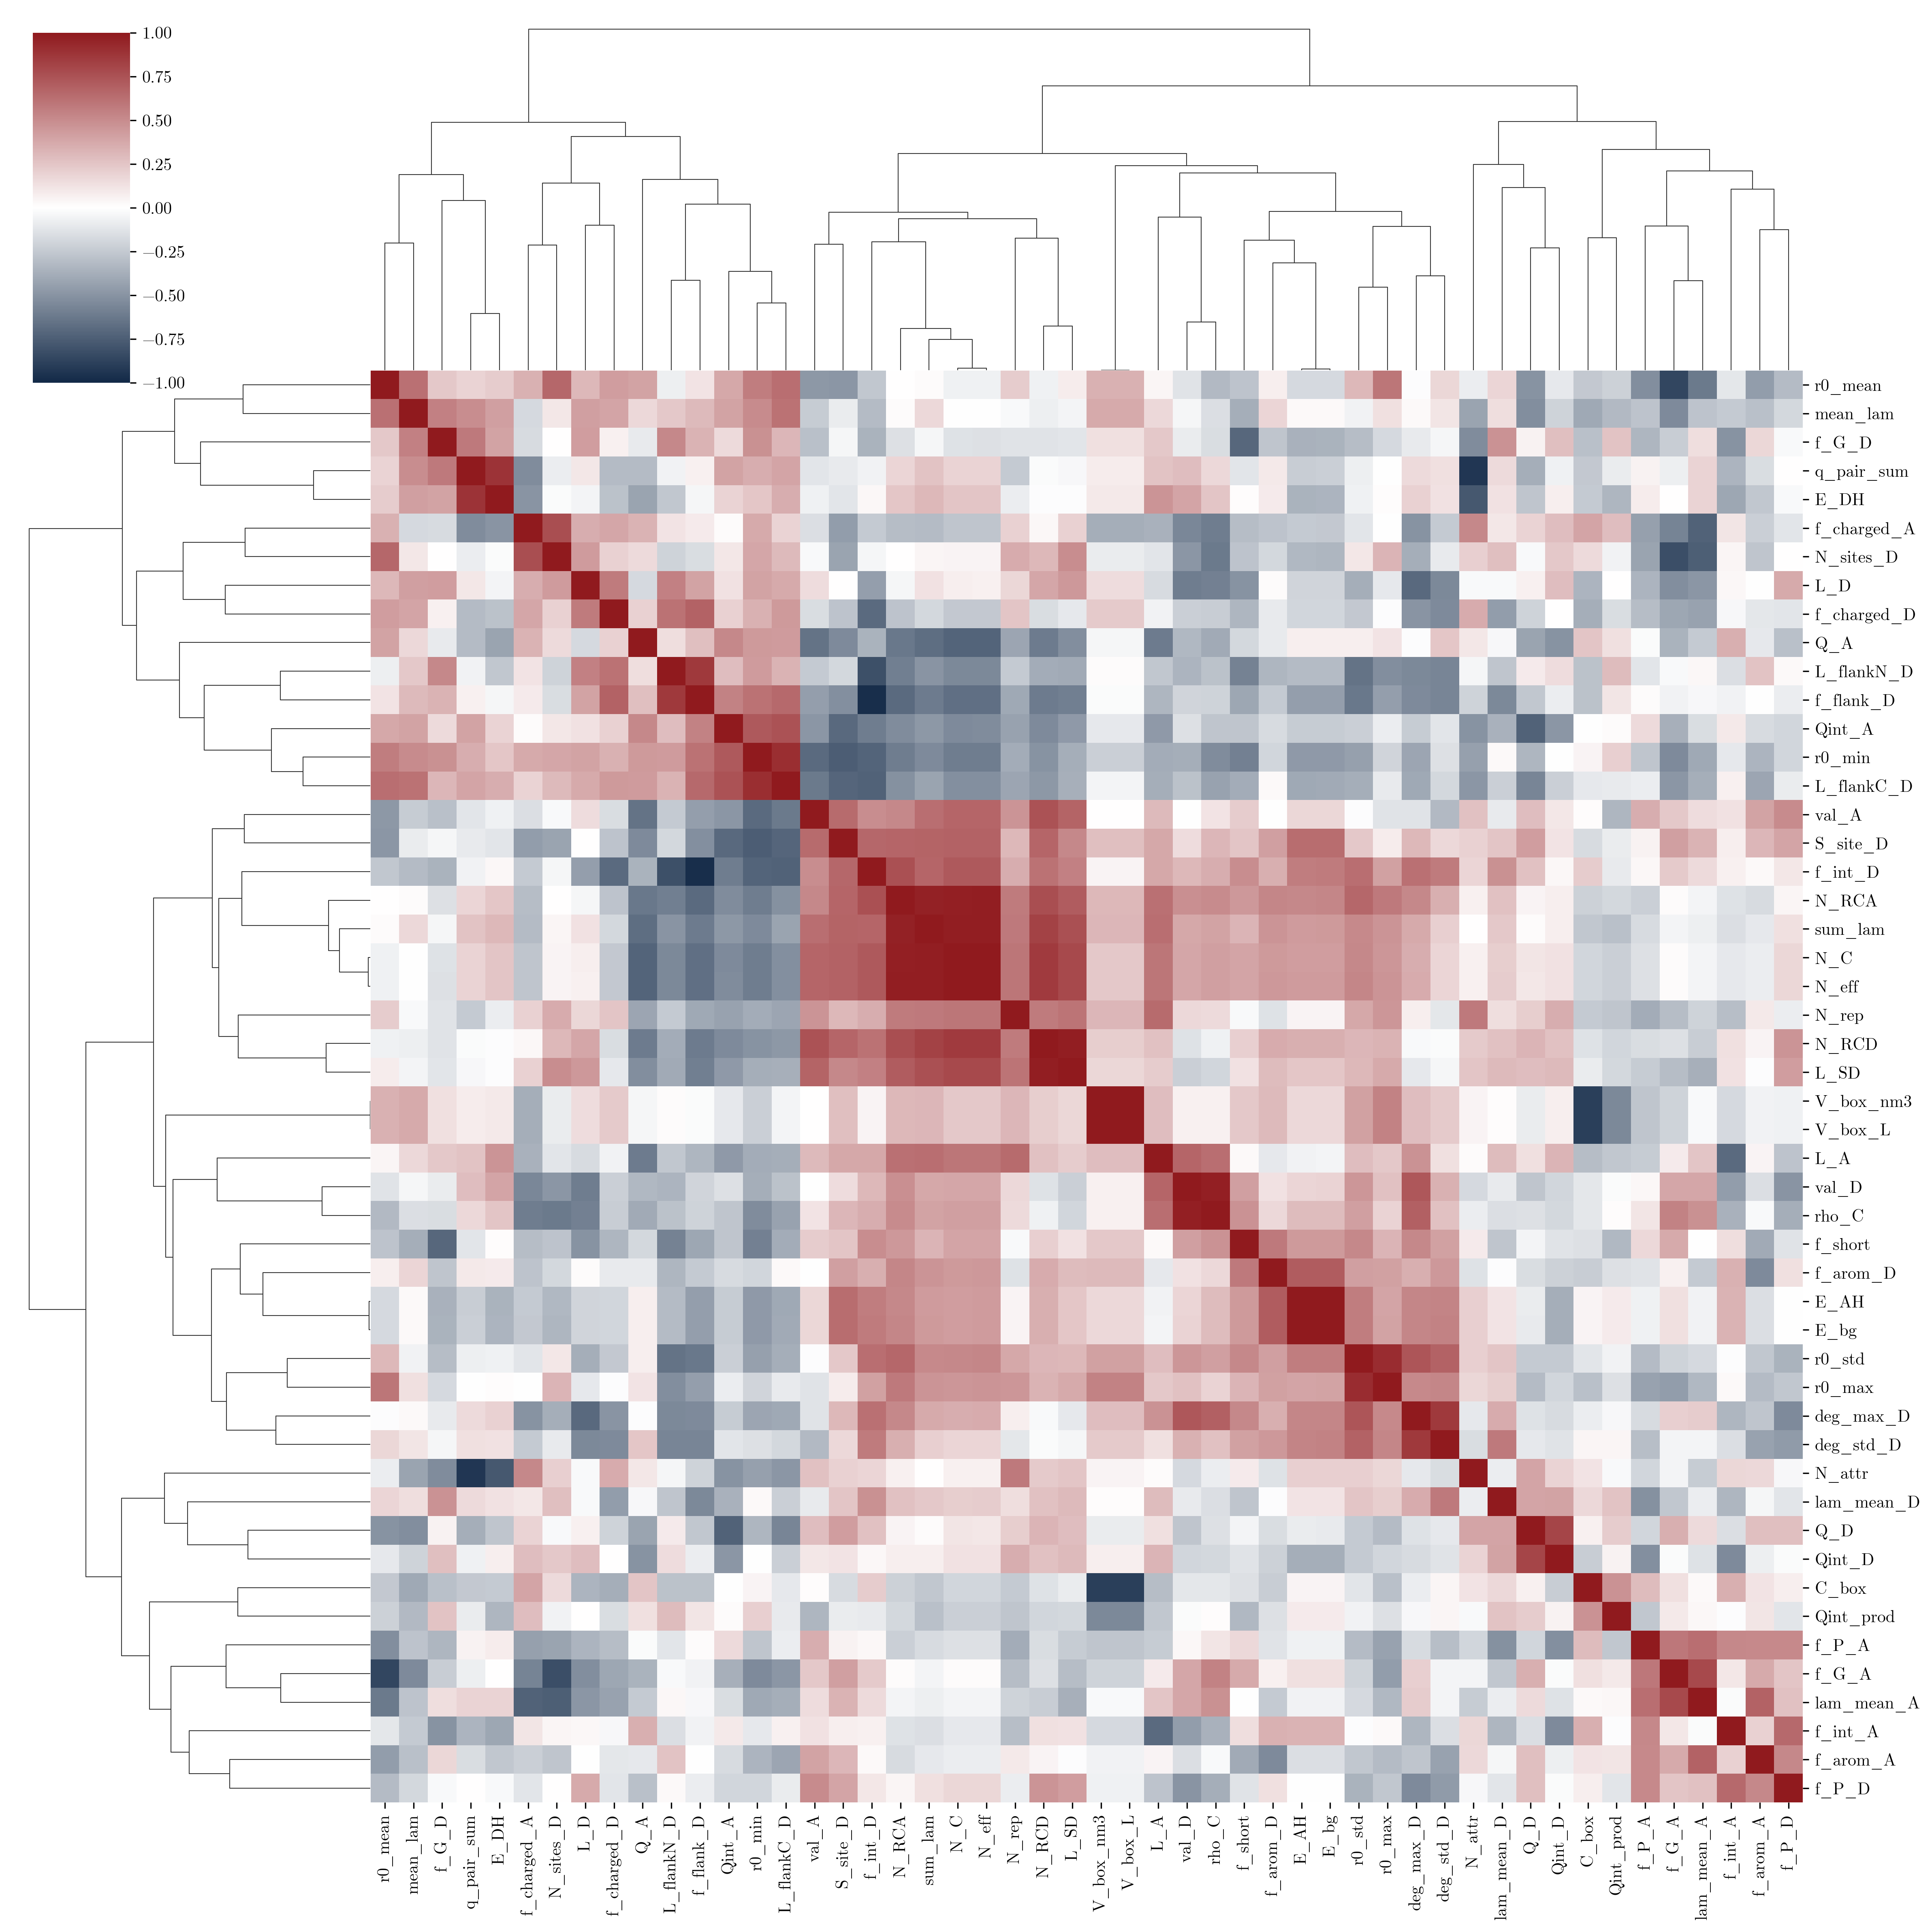

In [7]:
cg = sns.clustermap(X_num.corr(), figsize=(16,16), cmap=visualisation.cmap.diverging_cmap, vmin=-1, vmax=1)
cluster_col_order = [t._text for t in cg.ax_heatmap.get_xticklabels()][::-1]

(-1.0, 1.0)

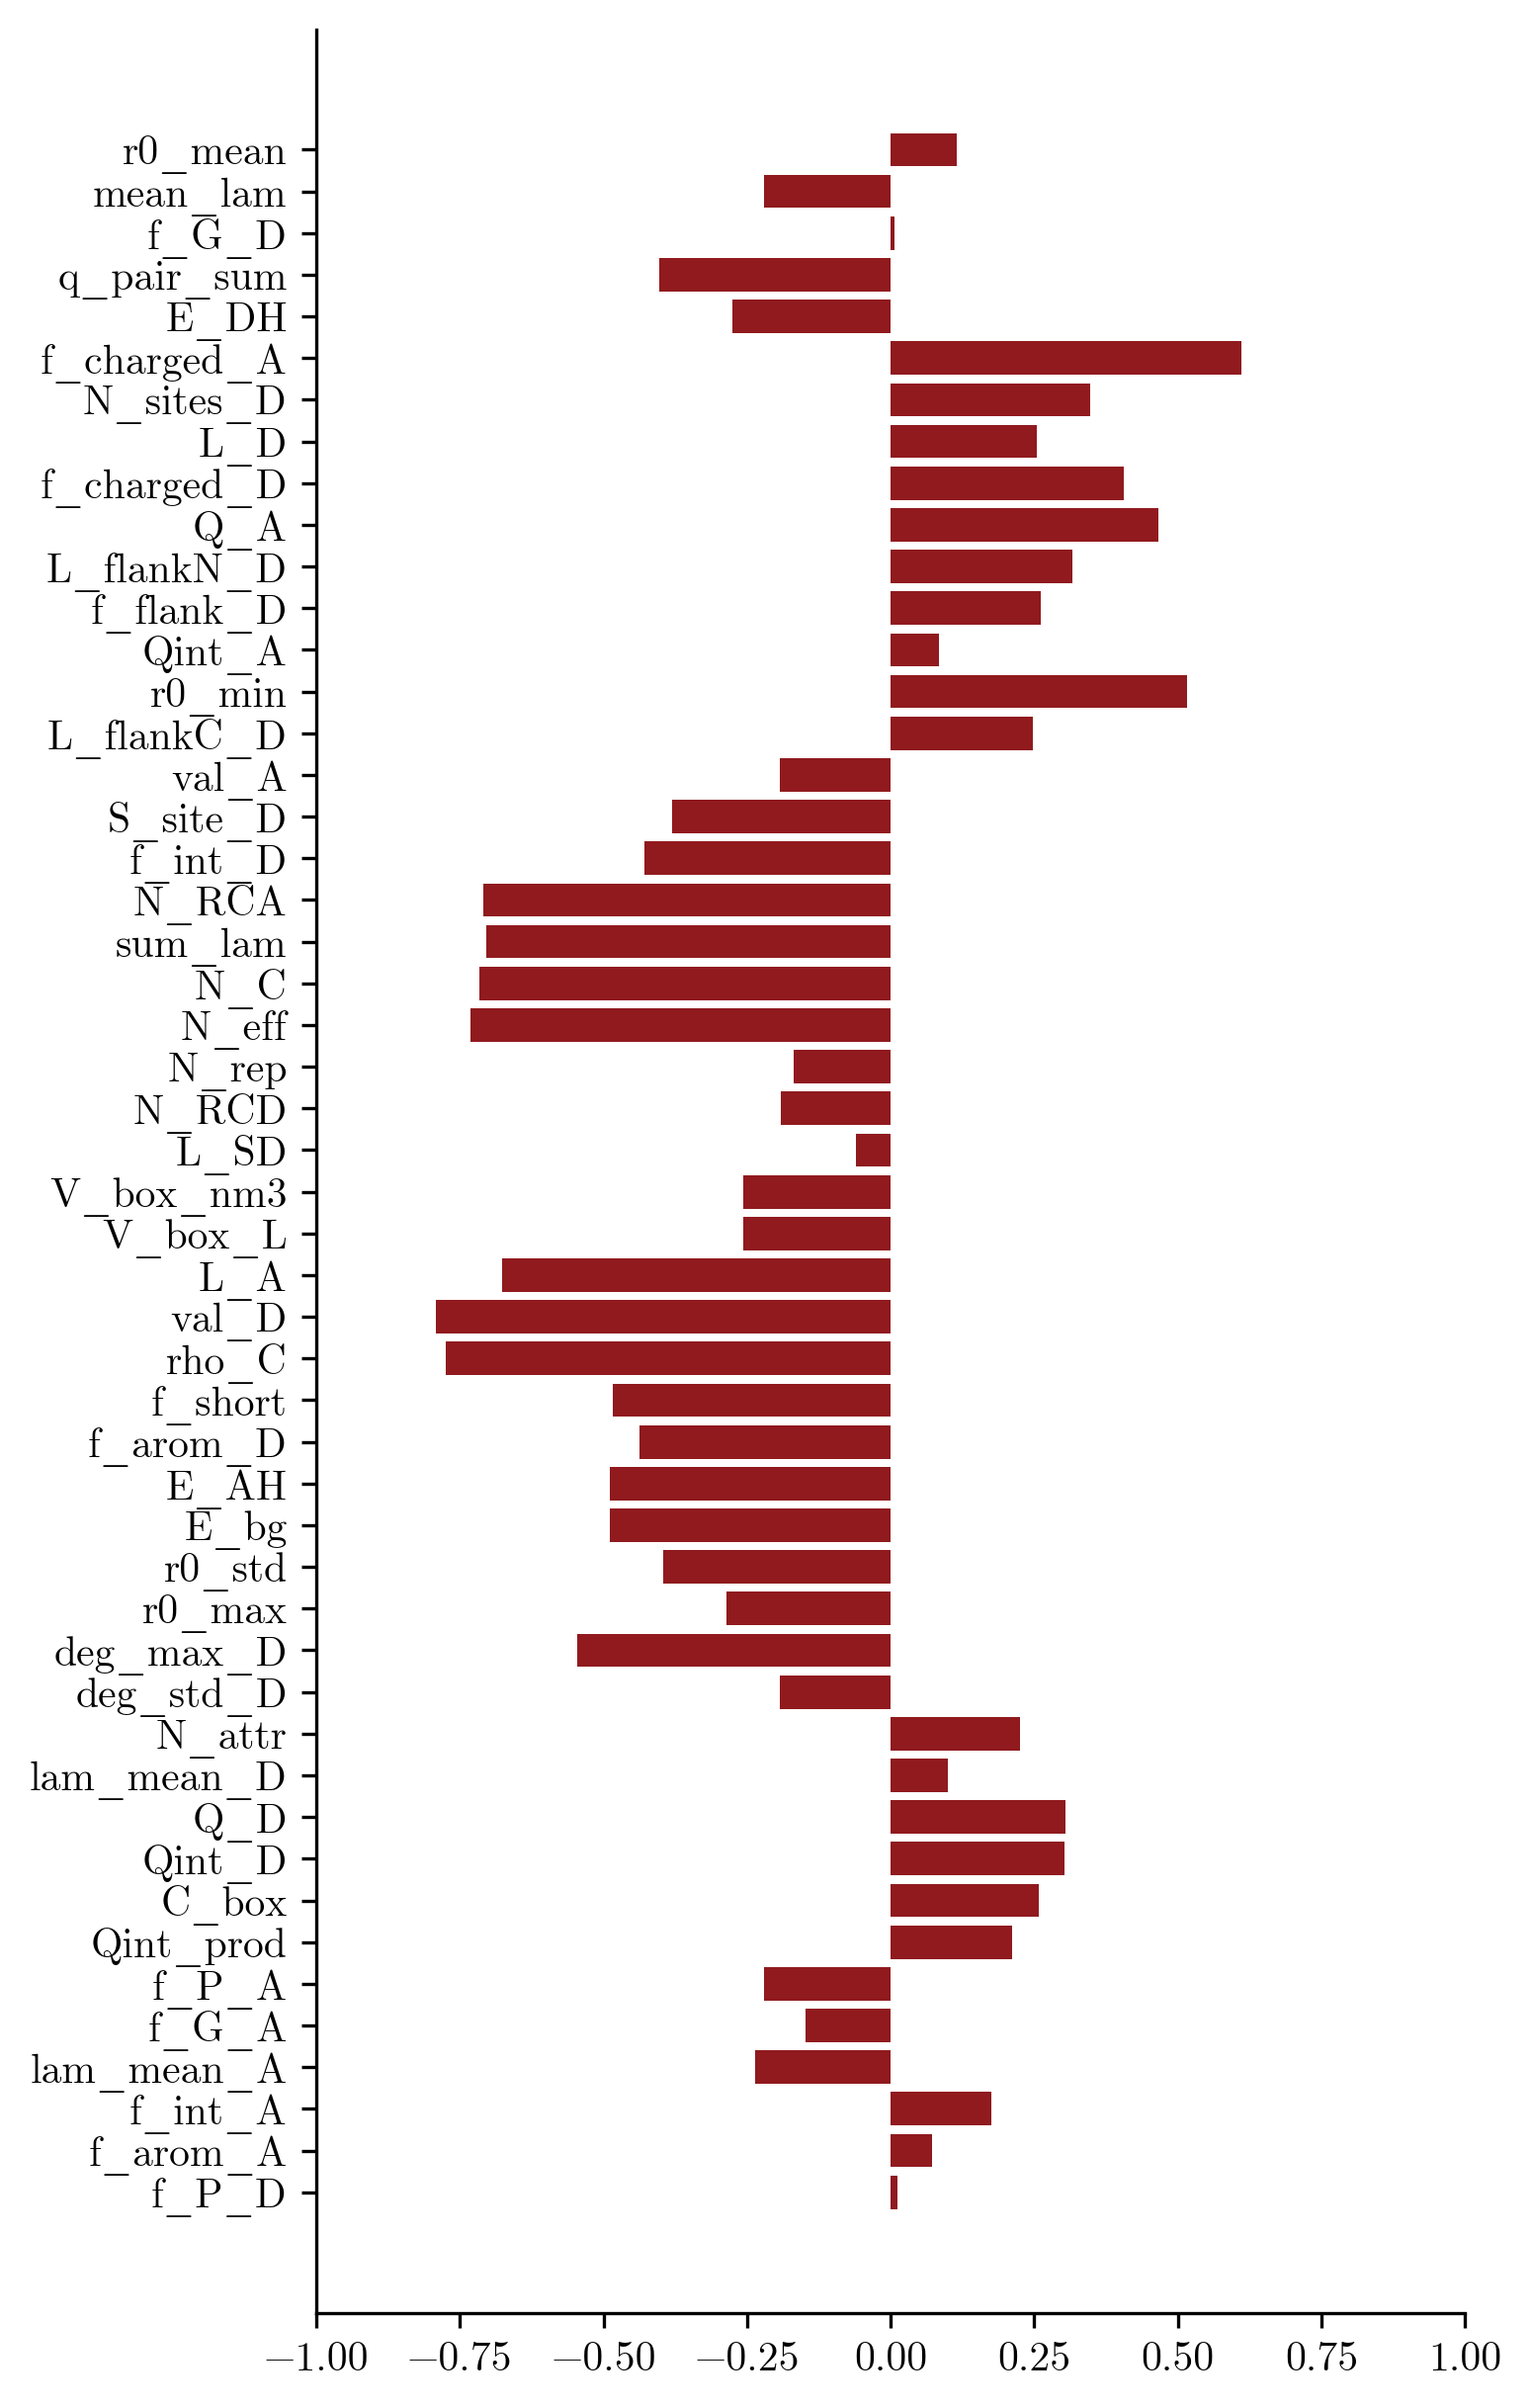

In [13]:
k_star = Y.groupby('System').apply(k_star_ish).loc[X_num.index]
X_corr = X_num.corrwith(k_star, method='spearman')

X_corr = X_corr.loc[cluster_col_order]

plt.figure(figsize=(5,10))
plt.barh(X_corr.index, X_corr)
plt.xlim(-1,1)

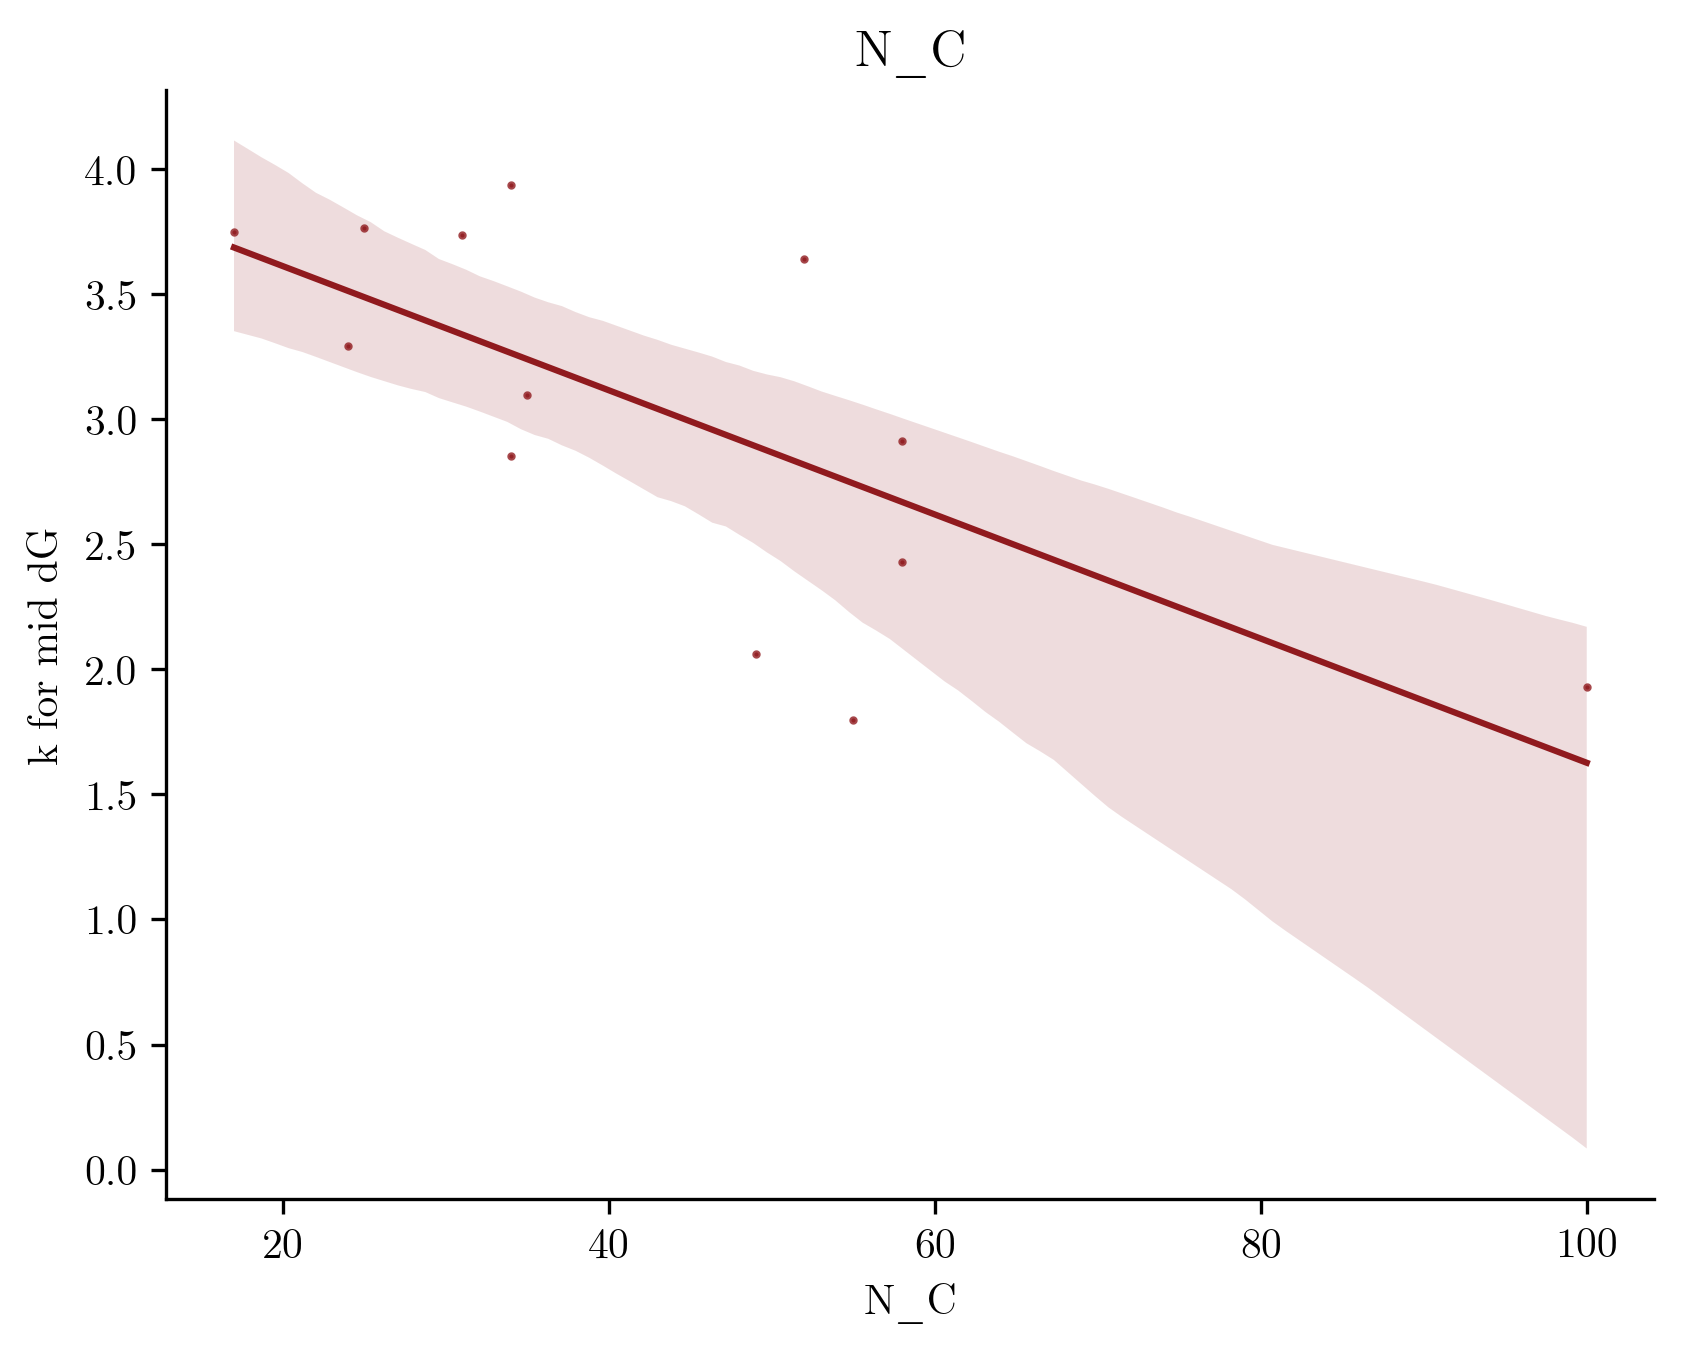

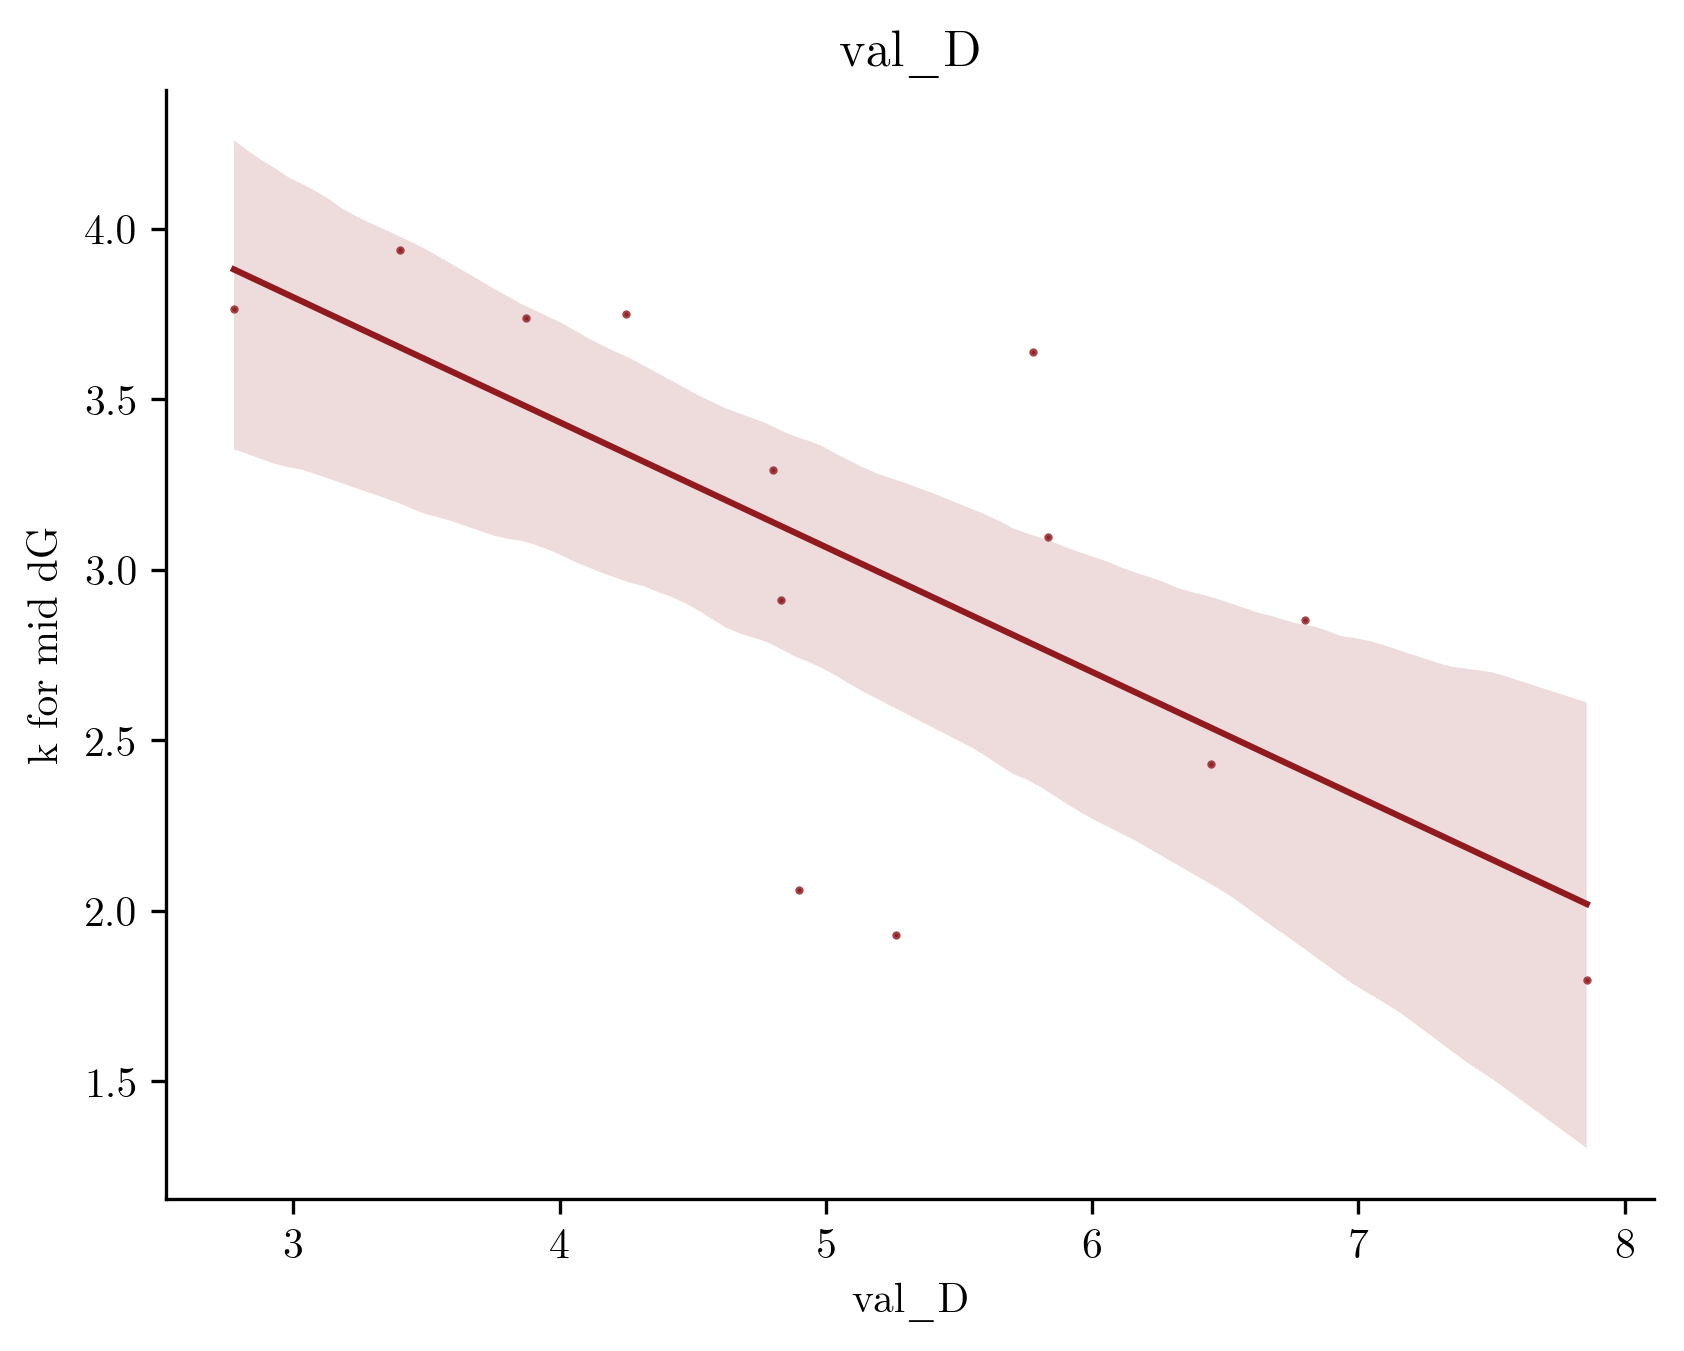

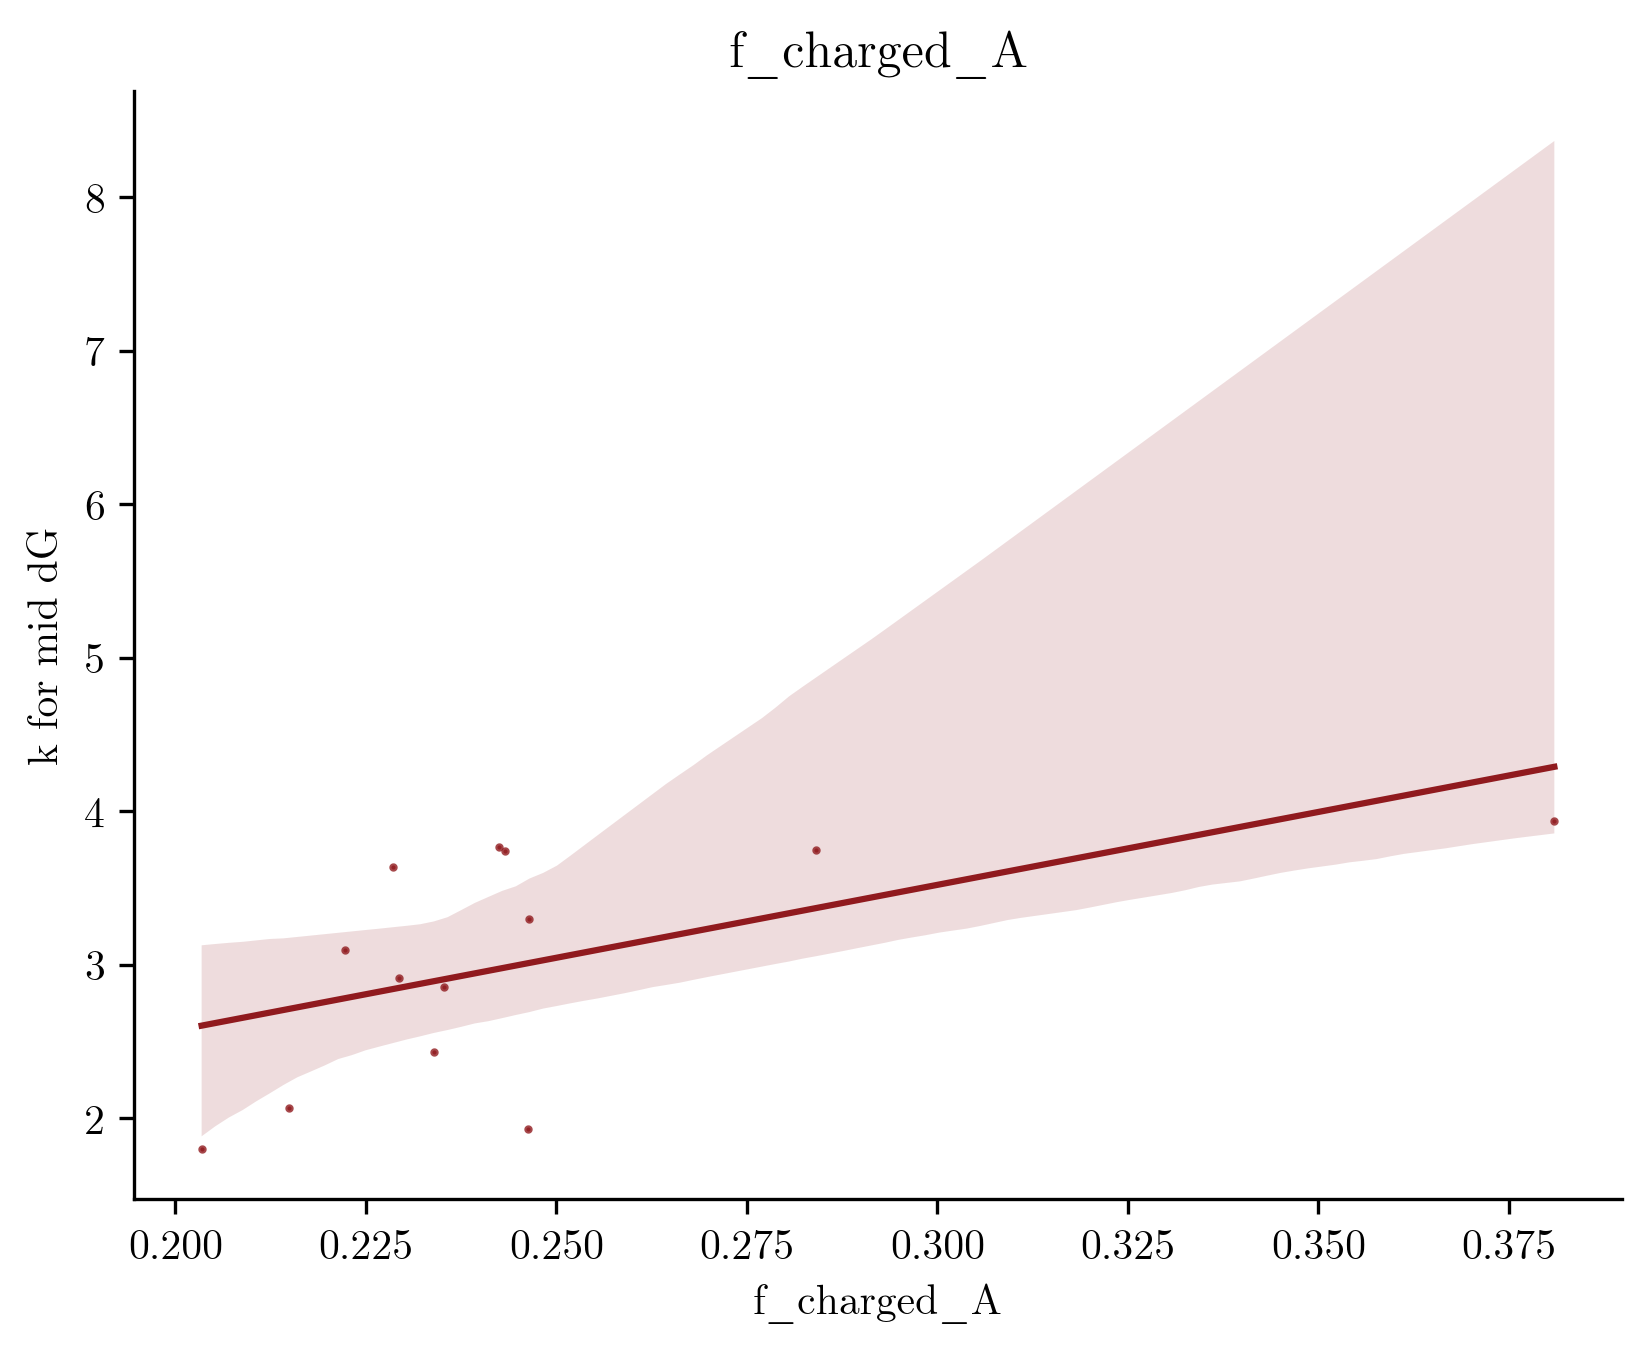

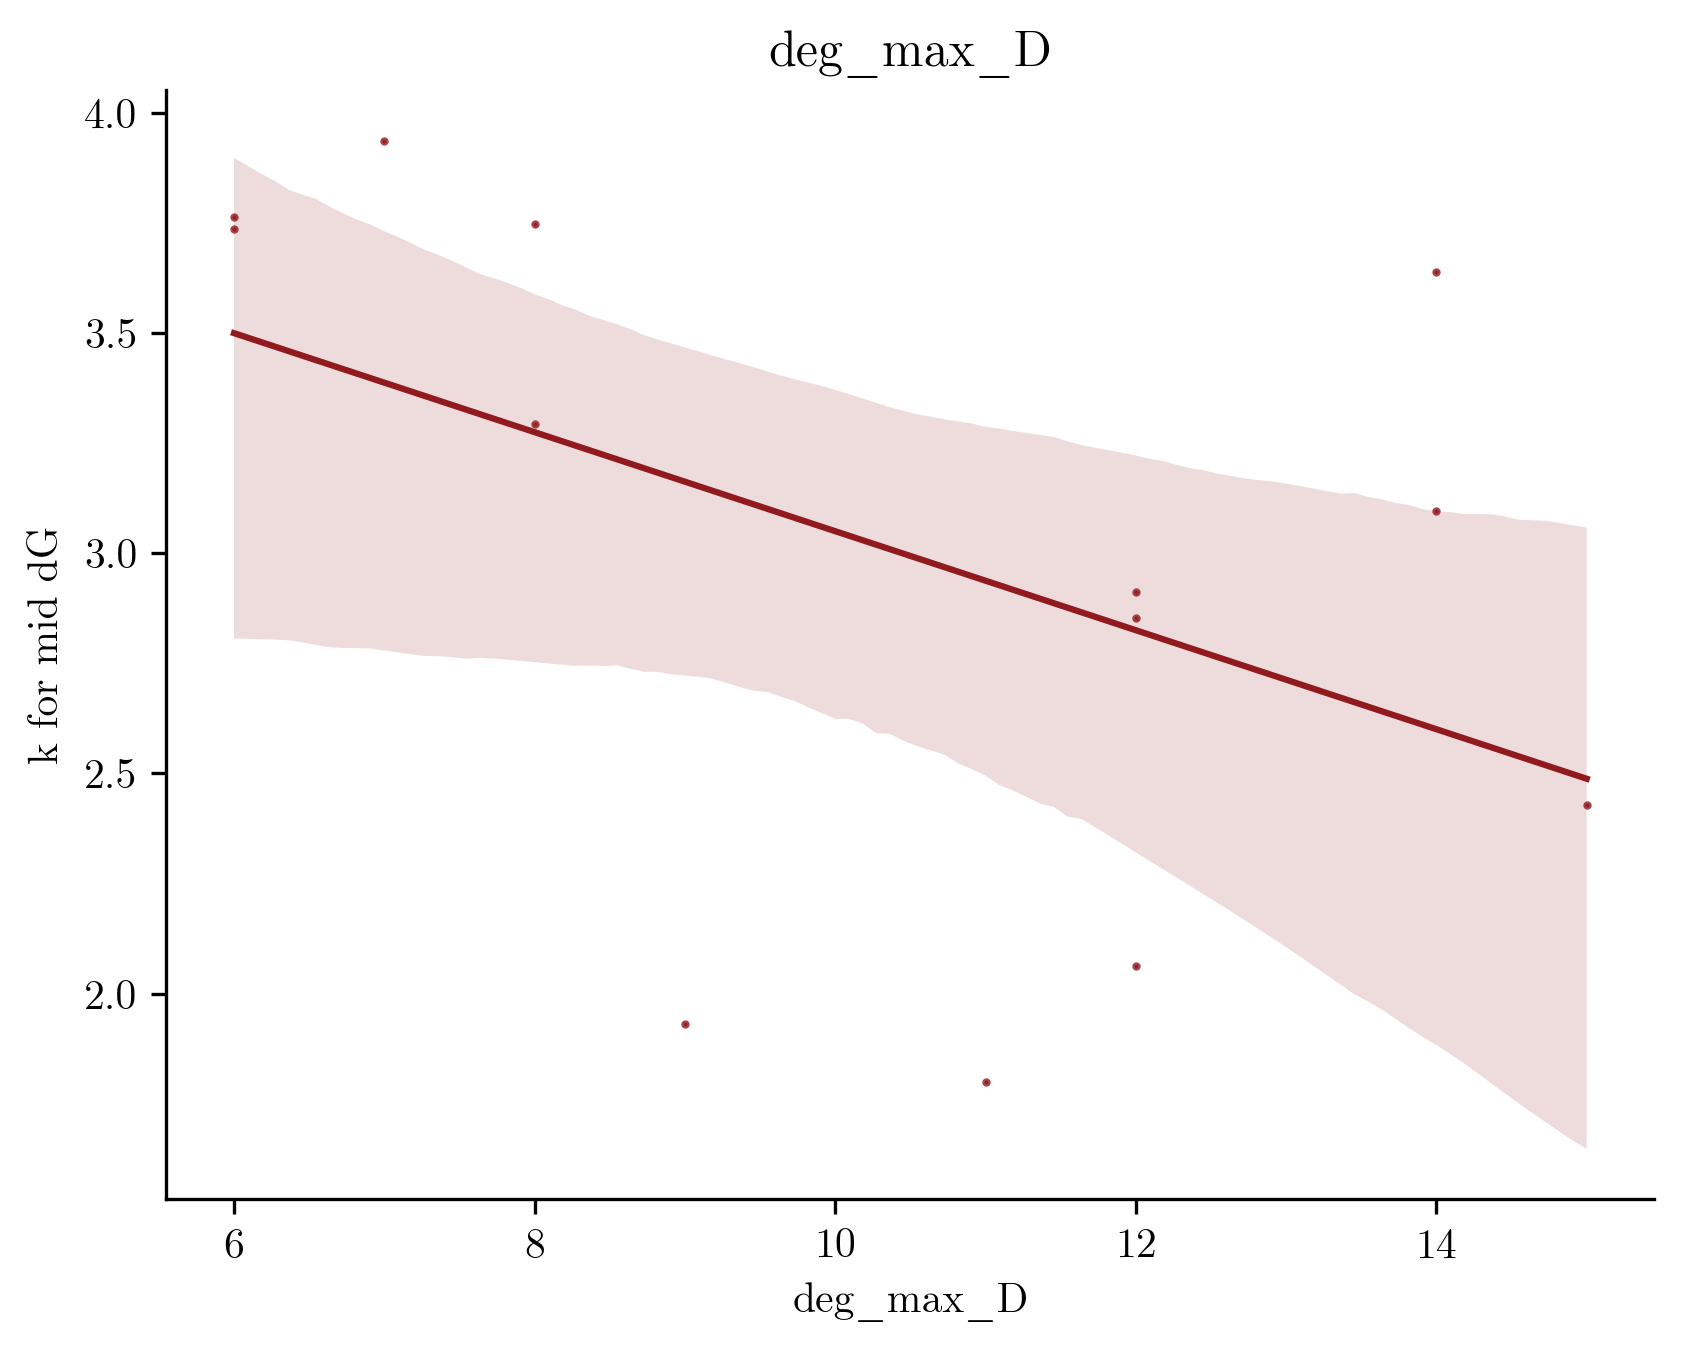

In [25]:
for col in ['N_C', 'val_D', 'f_charged_A', 'deg_max_D']:
    sns.regplot(x=X_num[col], y=k_star)
    plt.ylabel("k for mid dG")
    plt.title(col)
    plt.show()

In [49]:
import numpy as np
from sklearn.model_selection import train_test_split


X_train, X_test, y_train, y_test = train_test_split(
    X[['N_C', 'val_D', 'f_charged_A', 'deg_max_D']], k_star, test_size=0.20,
)

print(f"Full Dataset:  X shape = {X.shape}, y shape = {k_star.shape}")
print(f"Training Set:  X_train shape = {X_train.shape}, y_train shape = {y_train.shape}")
print(f"Testing Set:   X_test shape = {X_test.shape}, y_test shape = {y_test.shape}")

from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)
model.fit(X_train, y_train)

predictions = model.predict(X_test)
((predictions - y_test)**2).sum()**0.5/len(y_test)

Full Dataset:  X shape = (13, 52), y shape = (13,)
Training Set:  X_train shape = (10, 4), y_train shape = (10,)
Testing Set:   X_test shape = (3, 4), y_test shape = (3,)


0.41707592273676797